In [1]:
# Connect Google Colab to Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Need pandas library for this
import pandas as pd

In [17]:
# Find your uploaded files
import os
folder = '/content/drive/MyDrive/BMEN 600/EHG Dataset (1)/files/icehg-ds/1.0.1'

In [18]:
# Now that we have found the correct path we can read Table 1 about induced deliveries
with open(folder + '/Table_1.txt', 'r') as file:
    print(file.read()[:1500])

﻿+------------------+--------+----------------+--------------------+---------------+----------------+--------------------+---------------+--------+-------------+-----------+---------+
| Induced          | Age    | Early          | Recording          | Weight        | Later          | Recording          | Weight        | Height | Placental   | Gestation | Newborn |
| deliveries       |        | record         | time (early)       | (early)       | record         | time (later)       | (later)       |        | position    |           | weight  |
+------------------+--------+----------------+--------------------+---------------+----------------+--------------------+---------------+--------+-------------+-----------+---------+
| Pregnancy No.    | [year] | ID             | [week]             | [kg]          | ID             | [week]             | [kg]          | [cm]   | [front/end] | [week]    | [g]     |
+------------------+--------+----------------+--------------------+---------------+-

In [19]:
# Now same thing for Table 2- Cesarean Deliveries
with open(folder + '/Table_2.txt', 'r') as file:
    print(file.read()[:1500])

﻿+------------------+--------+----------------+--------------------+---------------+----------------+--------------------+---------------+--------+-------------+-----------+---------+
| Cesarean         | Age    | Early          | Recording          | Weight        | Later          | Recording          | Weight        | Height | Placental   | Gestation | Newborn |
| deliveries       |        | record         | time (early)       | (early)       | record         | time (later)       | (later)       |        | position    |           | weight  |
+------------------+--------+----------------+--------------------+---------------+----------------+--------------------+---------------+--------+-------------+-----------+---------+
| Pregnancy No.    | [year] | ID             | [week]             | [kg]          | ID             | [week]             | [kg]          | [cm]   | [front/end] | [week]    | [g]     |
+------------------+--------+----------------+--------------------+---------------+-

In [21]:
# Now same thing for Table 3- Induced-Cesarean Deliveries
with open(folder + '/Table_3.txt', 'r') as file:
    print(file.read()[:1500])

﻿+--------------------+--------+----------------+--------------------+---------------+----------------+--------------------+---------------+--------+-------------+-----------+---------+
| Induced-cesarean   | Age    | Early          | Recording          | Weight        | Later          | Recording          | Weight        | Height | Placental   | Gestation | Newborn |
| deliveries         |        | record         | time (early)       | (early)       | record         | time (later)       | (later)       |        | position    |           | weight  |
+--------------------+--------+----------------+--------------------+---------------+----------------+--------------------+---------------+--------+-------------+-----------+---------+
| Pregnancy No.      | [year] | ID             | [week]             | [kg]          | ID             | [week]             | [kg]          | [cm]   | [front/end] | [week]    | [g]     |
+--------------------+--------+----------------+--------------------+-----

In [ ]:
# Now we are going to try to get an example EHG signal

In [22]:
# Install the library for reading EHG signals
!pip install wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 9.0 MB/s eta 0:00:00


In [34]:
# Import other libraries
import numpy as np
import matplotlib.pyplot as plt
import random

In [23]:
# Load one EHG recording- This is an early EHG recording from the induced delivery group
import wfdb

folder = '/content/drive/MyDrive/BMEN 600/EHG Dataset (1)/files/icehg-ds/1.0.1'

record_path = folder + '/early_induced/icehg1185'

record = wfdb.rdrecord(record_path)

print(record.sig_name)
print(record.fs)

['S1', 'S1_DOCFILT-4-0.08-5', 'S2', 'S2_DOCFILT-4-0.08-5', 'S3', 'S3_DOCFILT-4-0.08-5']
20


Our output showed us the 3 different signals and each one had a raw signal and a filtered signal. And the sampling frequency was 20 Hz


We want to plot the signal/time not the sampling number. So we have to get seconds from the Hz

In [25]:
# Extract the raw S1 signal
signal = record.p_signal[:, 0]

print(signal[:10])

[-0.04440375 -0.03936828 -0.04882887 -0.05905241 -0.06027314 -0.05943389
 -0.06065461 -0.06172274 -0.06248569 -0.06301976]


In [27]:
# Create a time variable from the sampling freq

time = np.arange(len(signal)) / record.fs / 60

print(time[:10])

[0.         0.00083333 0.00166667 0.0025     0.00333333 0.00416667
 0.005      0.00583333 0.00666667 0.0075    ]


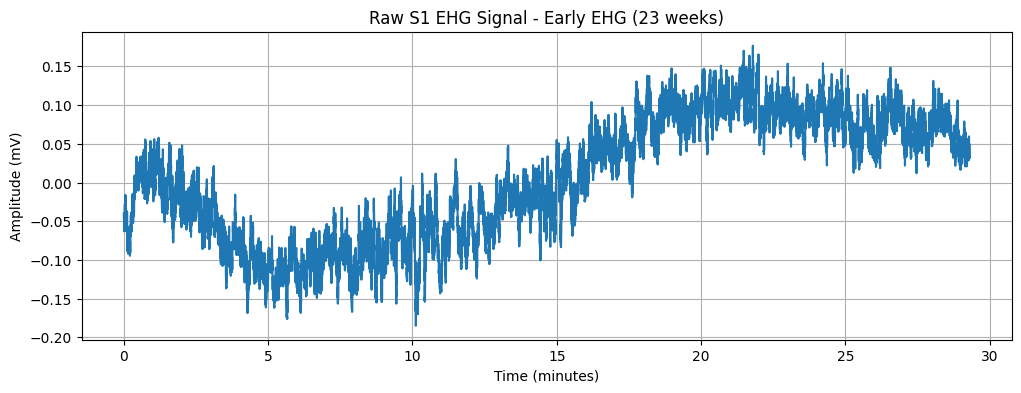

In [31]:
# Plot the raw S1 signal
plt.figure(figsize=(12, 4))

plt.plot(time, signal)

plt.xlabel('Time (minutes)')
plt.ylabel('Amplitude (mV)')
plt.title('Raw S1 EHG Signal - Early EHG (23 weeks)')
plt.grid()

plt.show()

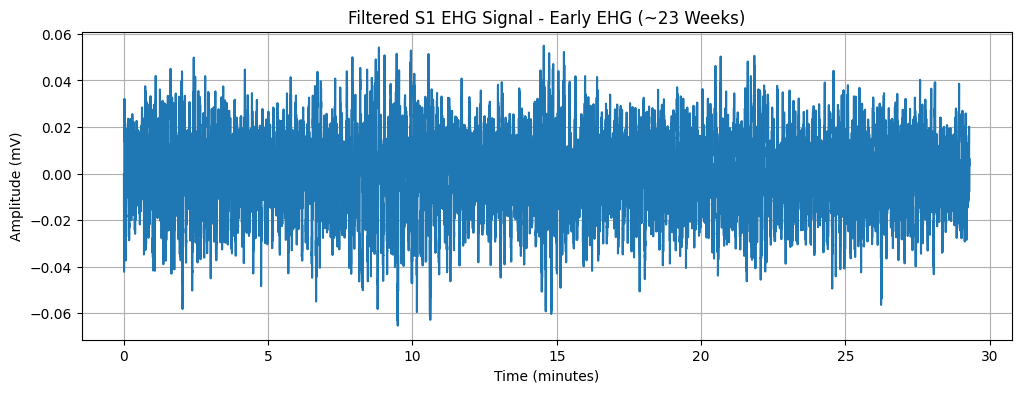

In [32]:
# Now we are going to do the filtered S1 signal

filtered_signal = record.p_signal[:, 1] #0 last time, 1 is the filtered

plt.figure(figsize=(12, 4))

plt.plot(time, filtered_signal)

plt.xlabel('Time (minutes)')
plt.ylabel('Amplitude (mV)')
plt.title('Filtered S1 EHG Signal - Early EHG (~23 Weeks)')
plt.grid()

plt.show()

We can see that the drift is much less in the filtered signal

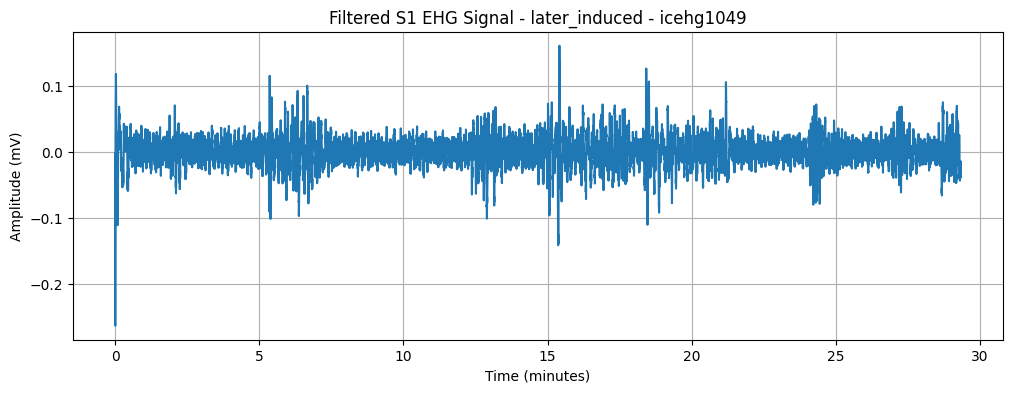

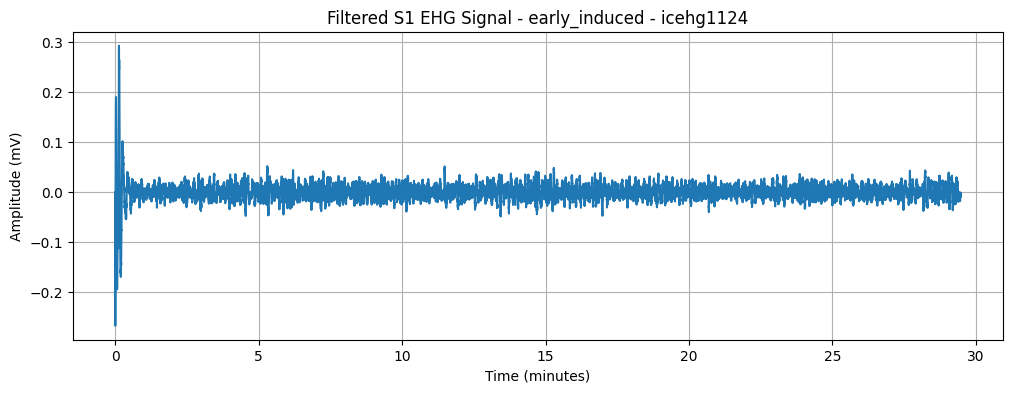

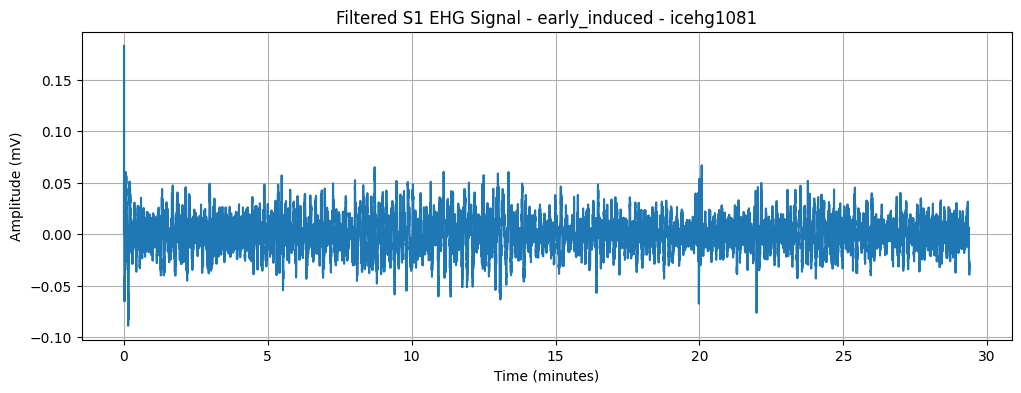

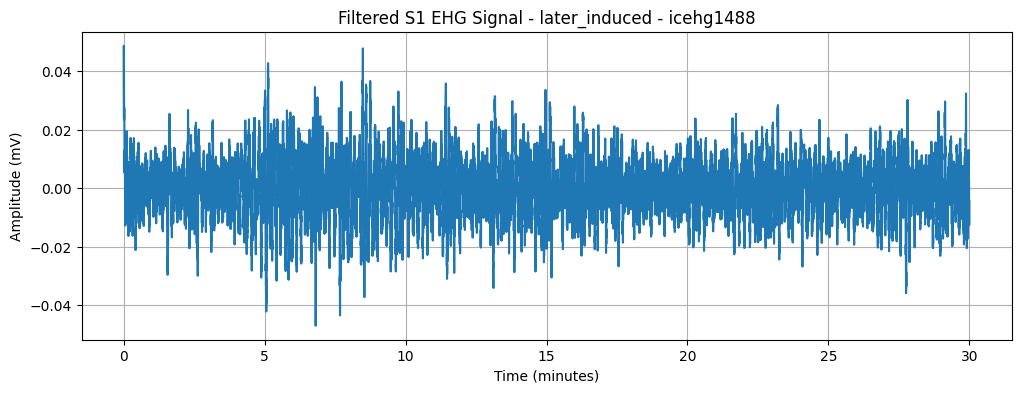

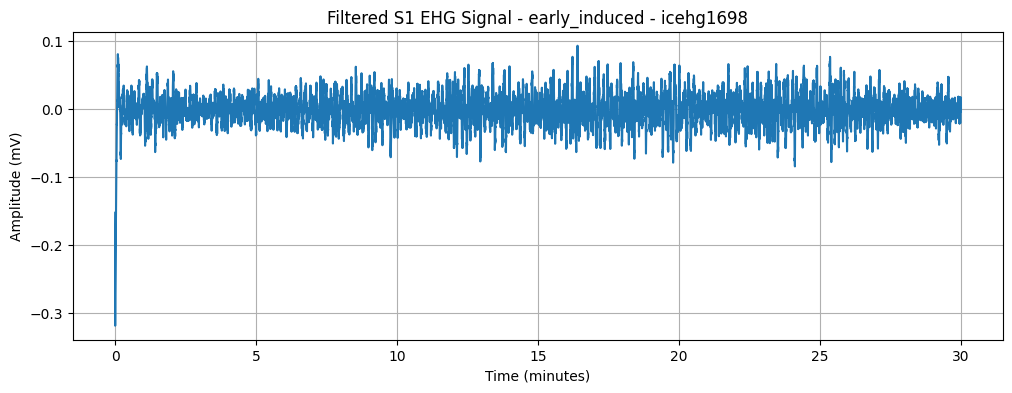

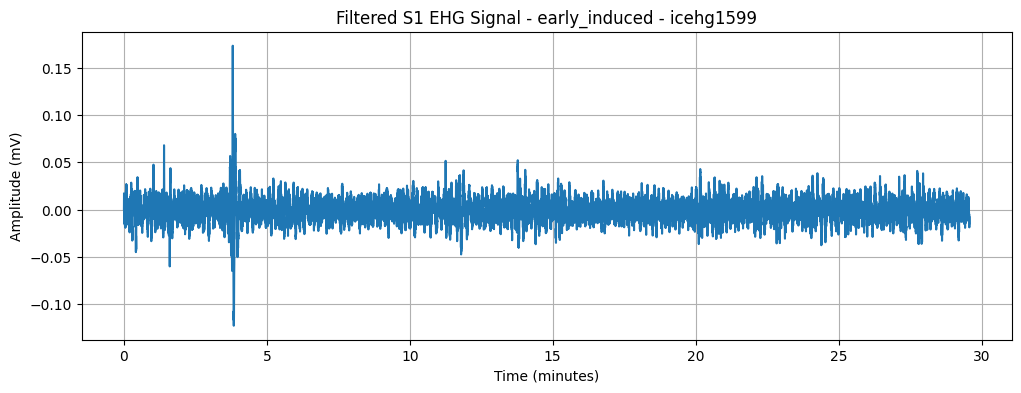

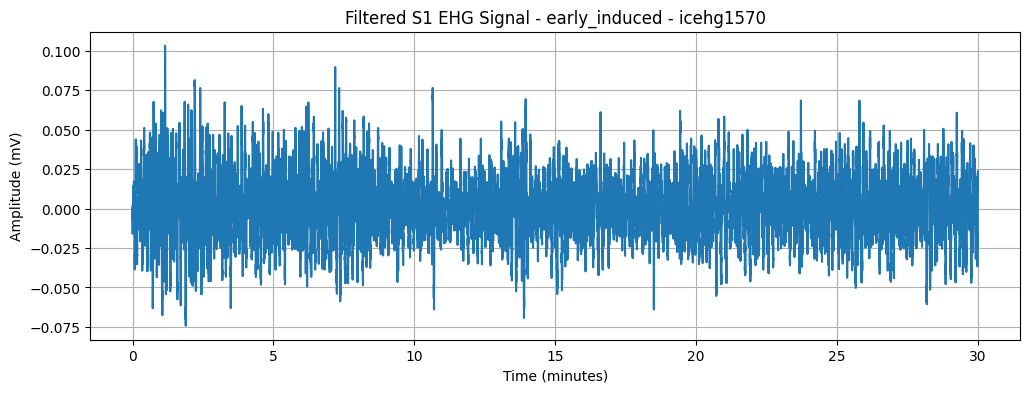

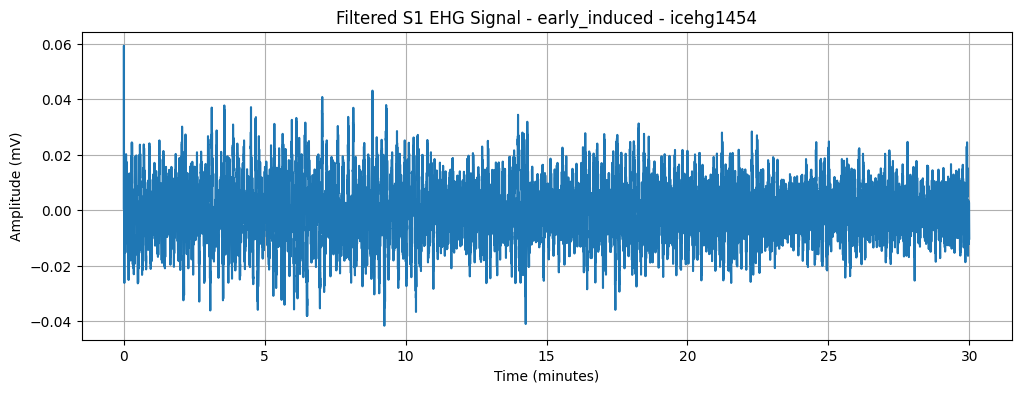

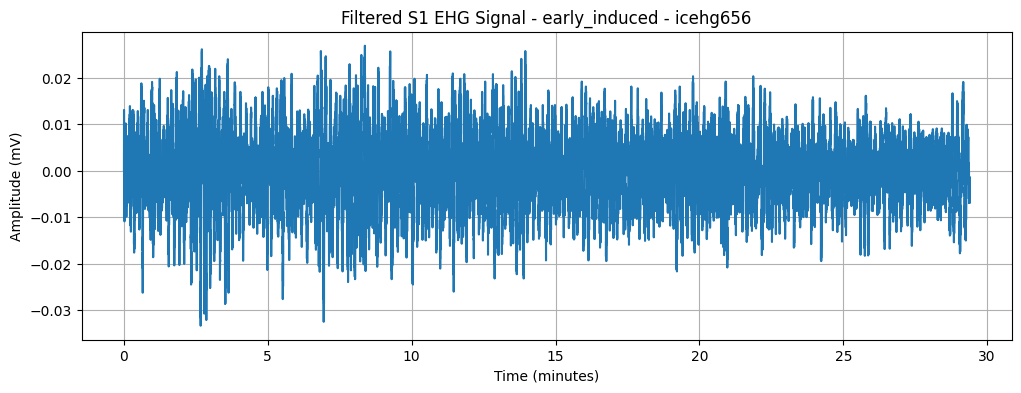

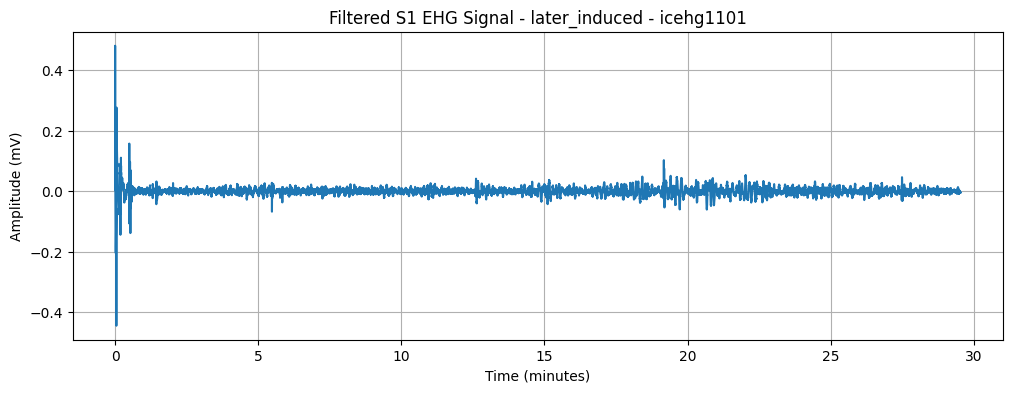

In [35]:
# Now we want to check 10 other random filtered S1 EHGs to make sure that the data is high quality

# 1. Find all EHG recordings in the dataset
folders = [
    'early_induced',
    'early_cesarean',
    'early_induced-cesarean',
    'later_induced',
    'later_cesarean',
    'later_induced-cesarean'
]

recordings = []

for subfolder in folders:
    path = os.path.join(folder, subfolder)

    for filename in os.listdir(path):
        if filename.endswith('.hea'):
            record_name = filename.replace('.hea', '')
            recordings.append((subfolder, record_name))

# 2. Randomly select 10 recordings
random.seed(42)
selected = random.sample(recordings, 10)

# 3. Plot each filtered S1 signal
for subfolder, record_name in selected:

    record_path = os.path.join(folder, subfolder, record_name)
    record = wfdb.rdrecord(record_path)

    filtered_signal = record.p_signal[:, 1]

    time = np.arange(len(filtered_signal)) / record.fs / 60

    plt.figure(figsize=(12, 4))

    plt.plot(time, filtered_signal)

    plt.xlabel('Time (minutes)')
    plt.ylabel(f'Amplitude ({record.units[1]})')
    plt.title(f'Filtered S1 EHG Signal - {subfolder} - {record_name}')
    plt.grid()

    plt.show()